<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Símbolo de Python -->
            <img
                src="https://cdn3.emoji.gg/emojis/1887_python.png"
                style="margin-bottom:-5px"
                width="30px" 
                height="30px"
            >
            <!-- Título -->
            Python para Geólogos
            <!-- Versión -->
            <img 
                src="https://img.shields.io/github/release/kevinalexandr19/manual-python-geologia.svg?style=flat&label=&color=blue"
                style="margin-bottom:-2px" 
                width="40px"
            >
        </strong>
    </span>
    <br>
    <span>
        <!-- Github del proyecto -->
        <a href="https://github.com/kevinalexandr19/manual-python-geologia" target="_blank">
            <img src="https://img.shields.io/github/stars/kevinalexandr19/manual-python-geologia.svg?style=social&label=Github Repo">
        </a>
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/github/license/kevinalexandr19/manual-python-geologia.svg?color=forestgreen">
        &nbsp;&nbsp;
        <!-- Release date -->
        <img src="https://img.shields.io/github/release-date/kevinalexandr19/manual-python-geologia?color=gold">
    </span>
    <br>
    <span>
        <!-- Perfil de LinkedIn -->
        <a target="_blank" href="https://www.linkedin.com/in/kevin-alexander-gomez/">
            <img src="https://img.shields.io/badge/-Kevin Alexander Gomez-5eba00?style=social&logo=linkedin">
        </a>
        &nbsp;&nbsp;
        <!-- Perfil de Github -->
        <a target="_blank" href="https://github.com/kevinalexandr19">
            <img src="https://img.shields.io/github/followers/kevinalexandr19.svg?style=social&label=kevinalexandr19&maxAge=2592000">
        </a>
    </span>
    <br>
</div>

***

<span style="color:lightgreen; font-size:25px">**PG301 - Geoestadística** </span>

Bienvenido al curso!!!

Vamos a revisar las bases de la <span style="color:gold">geoestadística</span> usando ejemplos en Python. <br>
Es necesario que tengas un conocimiento previo en programación con Python, estadística y geología general.

<span style="color:gold; font-size:20px">**Introducción al Variograma** </span>

***
- [¿Qué es la estacionariedad?](#parte-1)
- [Semivariograma](#parte-2)
- [Ejemplo con porosidad y permeabilidad](#parte-3)
- [En conclusión...](#parte-4)

***

In [ ]:
import sys

if sys.platform == "emscripten":
    import piplite
    await piplite.install(['numpy', 'pandas', 'matplotlib', 'scipy'])

<a id="parte-1"></a>

### <span style="color:lightgreen">**¿Qué es la estacionariedad?**</span>
***

En geoestadística, usamos muestras distribuidas en el espacio para estudiar cómo cambian las propiedades entre lugares. Para reunir pares separados por distancias parecidas, necesitamos que su comportamiento sea comparable dentro del dominio elegido.

Con **estacionariedad de segundo orden**, la media y la varianza son constantes en el dominio y la covarianza depende del vector de separación, con su distancia y dirección. Para construir un semivariograma también podemos trabajar con una hipótesis más débil sobre los incrementos: media cero y varianza dependiente de la separación.

La estacionariedad es una decisión de modelamiento. Antes de calcular, pregunta si hay una tendencia, contactos entre facies o cambios en el soporte de las muestras. Mezclar dos dominios con medias distintas puede aumentar las diferencias entre pares aunque cada dominio tenga continuidad.

<a id="parte-2"></a>

### <span style="color:lightgreen">**Semivariograma**</span>
***

Para cada clase de distancia reunimos sus pares y promediamos la mitad de las diferencias al cuadrado.

$$
\widehat{\gamma}(h) =
\frac{1}{2N(h)} \sum_{(i,j)\ \in\ B_h} [z(u_i)-z(u_j)]^2
$$

$B_h$ contiene los pares de la clase con centro nominal $h$ y $N(h)$ es su conteo. Un par se cuenta una sola vez. En las figuras usamos la distancia **media** de los pares de cada clase. Una semivarianza pequeña indica que las parejas de esa separación suelen parecerse más.

**Antes de ejecutar.** Las muestras de 0 y 4 m tienen valores 1 y 3. Su contribución es $(1-3)^2/2=2$. También entran en la primera clase las muestras de 4 y 9 m. ¿Qué promedio esperas?

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.stats import norm, rankdata
from files.gamma import Variogram

ejemplo = Variogram([1, 3, 2, 5], [0, 4, 9, 16], lagDist=4)
ejemplo.pair_table()

Con un paso de 4 m, la primera clase reúne distancias mayores que 0 y hasta 6 m. Las siguientes son (6, 10], (10, 14] y (14, 18]. Mira `h_clase` para seguir cada par. La clase de 4 m contiene aportes 2 y 0.5, así que su semivarianza es 1.25. Una clase con un solo par también usa la división entre dos.

In [ ]:
ejemplo.lag_table()

<span style="color:gold">**Covarianza, correlograma y efecto pepita**</span>

Bajo estacionariedad de segundo orden, $\gamma(h)=C(0)-C(h)$. En el origen comparamos una variable consigo misma: $C(0)=\sigma^2$ y $\gamma(0)=0$. Si $\sigma^2>0$, el correlograma es $\rho(h)=C(h)/\sigma^2$.

La **pepita** $C_0$ representa el salto que puede existir entre cero y separaciones positivas muy pequeñas. Puede reflejar variación a una escala más fina que el muestreo o error de medición. Diferencias entre réplicas de una coordenada merecen revisarse aparte.

La **meseta** es $C_0+C$, donde $C$ es la contribución de la estructura espacial. El esférico llega a la meseta a la distancia $a$. El exponencial y el gaussiano se acercan gradualmente; en `gamma` mostramos su **alcance práctico** al 95% de la contribución $C$.

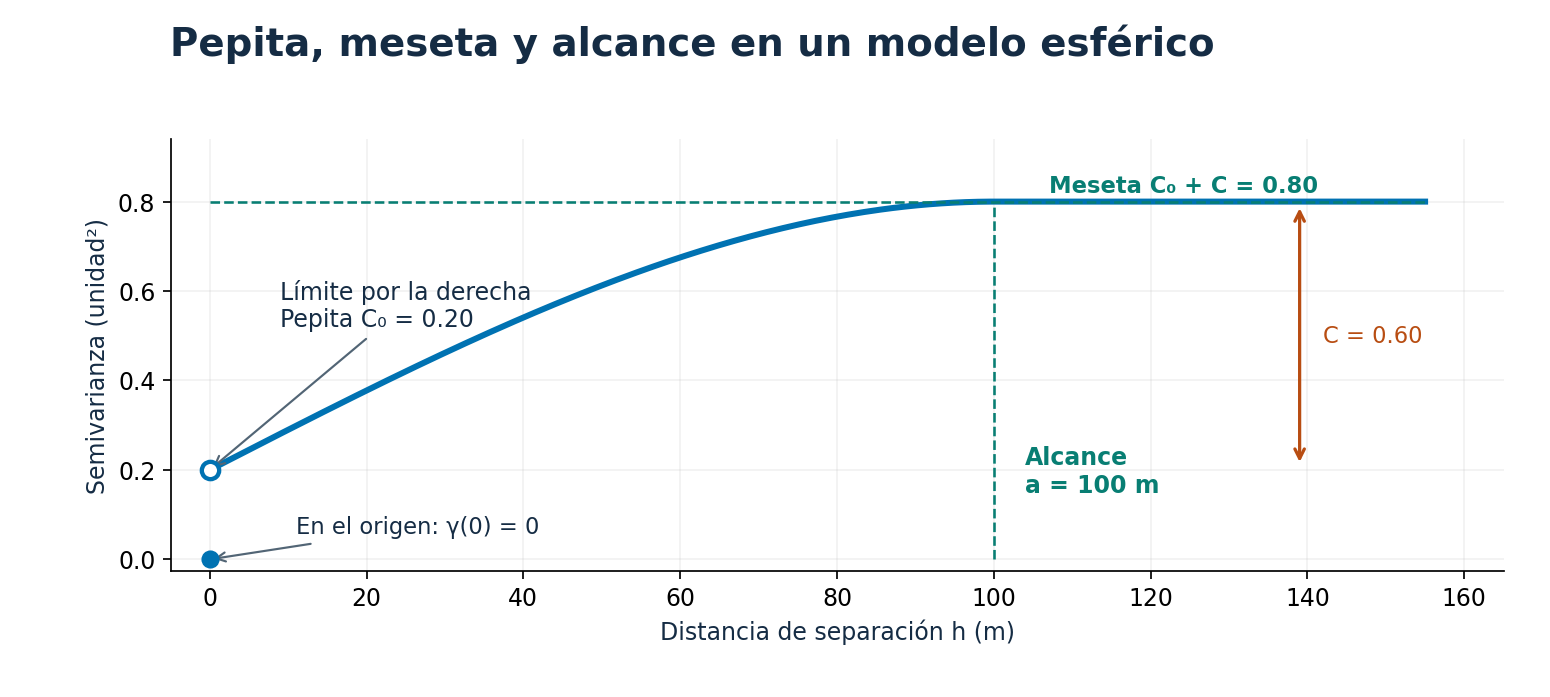

El círculo hueco marca el límite al acercarnos desde distancias positivas. El punto sólido marca γ(0).

[Camana y Deutsch, The Nugget Effect](https://geostatisticslessons.com/lessons/nuggeteffect)

<a id="parte-3"></a>

### <span style="color:lightgreen">**Ejemplo con porosidad y permeabilidad**</span>
***

Retomamos `data_variograma.csv`. Cada fila es una muestra con coordenadas (m), facies, porosidad y permeabilidad. La porosidad viene como fracción (0.10 equivale a 10%). Convertimos a porcentaje para la interpretación. Por tanto, la semivarianza de porosidad quedará en puntos porcentuales al cuadrado. La de permeabilidad queda en mD².

In [ ]:
data = pd.read_csv("files/data_variograma.csv")
columnas = ["X", "Y", "Porosidad", "Permeabilidad"]
validas = np.isfinite(data[columnas]).all(axis=1)
print(f"Filas con medidas completas: {validas.sum()} de {len(data)}")
data = data.loc[validas].assign(Porosidad_pct=lambda d: d["Porosidad"] * 100)
data.groupby("Facies")[["Porosidad_pct", "Permeabilidad"]].agg(["size", "mean", "std"]).round(2)

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(9.5, 4.3), sharex=True, sharey=True)
for ax, campo, unidad, escala in zip(
    ejes, ["Porosidad_pct", "Permeabilidad"], ["Porosidad (%)", "Permeabilidad (mD)"], [None, LogNorm()]
):
    figura = ax.scatter(data["X"], data["Y"], c=data[campo], cmap="viridis", norm=escala,
                        s=30, edgecolors="0.2", linewidths=.25)
    ax.set(xlabel="Este (m)", title=unidad, aspect="equal")
    fig.colorbar(figura, ax=ax, shrink=.78, label=unidad)
ejes[0].set_ylabel("Norte (m)")
fig.tight_layout()
plt.show()

Usaremos las mismas distancias para comparar el conjunto completo con arenisca y lutita por separado. El paso de 100 m es una escala inicial coherente con la cuadrícula visible. Limitamos los pares a 500 m para concentrarnos en las distancias cortas e intermedias.

`Variogram` recibe el valor y las dos coordenadas de **las mismas filas**. Obtendremos una curva por variable y dominio. El panel inferior muestra cuánta información entra en cada clase.

In [ ]:
grupos = {"Todas": data, "Arenisca": data.loc[data["Facies"] == "arenisca"],
          "Lutita": data.loc[data["Facies"] == "lutita"]}
variables = {"Porosidad_pct": "(puntos porcentuales)²", "Permeabilidad": "mD²"}
colores = {"Todas": "#526575", "Arenisca": "#0072B2", "Lutita": "#B84D12"}
fig, ejes = plt.subplots(2, 2, figsize=(10, 6), sharex=True,
                         gridspec_kw={"height_ratios": [2.7, 1]})
for j, (campo, unidad) in enumerate(variables.items()):
    ax, pares = ejes[:, j]
    for nombre, df in grupos.items():
        vg = Variogram(df[campo], df[["X", "Y"]], lagDist=100, max_lag=500)
        ax.plot(vg.mean_lag, vg.gamma, "o-", color=colores[nombre], label=nombre)
        pares.plot(vg.mean_lag, vg.pairs, "o-", color=colores[nombre], markersize=3)
    ax.set(title=campo.replace("_pct", ""), ylabel=unidad)
    pares.set(xlabel="Distancia media (m)", ylabel="Pares")
    ax.grid(alpha=.2)
    pares.grid(alpha=.2)
ejes[0, 0].legend(frameon=False)
fig.tight_layout()
plt.show()

En la comparación por facies cambia la población, su dispersión y el número de pares disponibles. La curva de todas las muestras incluye pares que cruzan contactos. Un conteo grande da más información descriptiva, aunque los pares puedan compartir muestras.

**Comprobar la dirección.** Tomemos arenisca y comparemos norte–sur con este–oeste. En coordenadas planas, `azimuth=0` sigue el eje norte–sur y `90` el eje este–oeste. Usamos la misma tolerancia angular y contamos los pares en ambos sentidos. Diferencias de curva pueden sugerir anisotropía o reflejar cómo está distribuido el muestreo.

In [ ]:
arena = grupos["Arenisca"]
direcciones = {}
for nombre, az in [("Norte–sur", 0), ("Este–oeste", 90)]:
    direcciones[nombre] = Variogram(arena["Porosidad_pct"], arena[["X", "Y"]],
                                   lagDist=100, max_lag=500, azimuth=az,
                                   angle_tolerance=22.5).lag_table()
pd.concat(direcciones, names=["Dirección"]).round(2)

**Puntuaciones normales (opcional).** Esta transformación asigna a cada rango un cuantil de la normal estándar. Puede servir cuando el flujo posterior requiere esa distribución. El variograma se puede calcular directamente en las unidades originales, como hicimos arriba. Aquí veremos cómo cambia al transformar la porosidad de arenisca.

In [ ]:
valores = arena["Porosidad_pct"].to_numpy()
puntuaciones = norm.ppf((rankdata(valores, method="average") - .5) / len(valores))
fig, ejes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True)
for ax, z, unidad, etiqueta in zip(
    ejes, [valores, puntuaciones], ["(puntos porcentuales)²", "(puntuación normal)²"],
    ["Porosidad original", "Porosidad transformada"]
):
    vg = Variogram(z, arena[["X", "Y"]], lagDist=100, max_lag=500)
    ax.plot(vg.mean_lag, vg.gamma, "o-", color="#087E73")
    ax.set(title=etiqueta, xlabel="Distancia media (m)", ylabel=unidad)
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

<a id="parte-4"></a>

### <span style="color:lightgreen">**En conclusión...**</span>
***

**Comprueba tu lectura.** Toma un punto de la curva y explica qué filas contribuyen a él. Cambia el paso y observa juntos la semivarianza y el conteo de pares. ¿Qué información adicional de geología o muestreo pedirías antes de dividir el dominio por facies?

Sigue con el [variograma a lo largo de un sondaje](pg301b_variograma1d.ipynb) para ajustar un modelo a esos puntos experimentales.